In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [4]:
dataset = pd.read_csv("cardataset.csv")
dataset.head(3)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner


In [5]:
dataset.isnull().sum()

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

In [7]:
dataset.describe()

,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


In [8]:
dataset.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
4335    False
4336    False
4337    False
4338    False
4339    False
Length: 4340, dtype: bool

In [13]:
#  Feature engineering: calculate car age from the year column; extract brand from the car name column 
dataset['car_age'] = 2026 - dataset['year']
dataset['brand'] = dataset['name'].str.split().str[0]
dataset

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,car_age,brand
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner,19,Maruti
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner,19,Maruti
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner,14,Hyundai
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner,9,Datsun
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner,12,Honda
...,...,...,...,...,...,...,...,...,...,...
4335,Hyundai i20 Magna 1.4 CRDi (Diesel),2014,409999,80000,Diesel,Individual,Manual,Second Owner,12,Hyundai
4336,Hyundai i20 Magna 1.4 CRDi,2014,409999,80000,Diesel,Individual,Manual,Second Owner,12,Hyundai
4337,Maruti 800 AC BSIII,2009,110000,83000,Petrol,Individual,Manual,Second Owner,17,Maruti
4338,Hyundai Creta 1.6 CRDi SX Option,2016,865000,90000,Diesel,Individual,Manual,First Owner,10,Hyundai


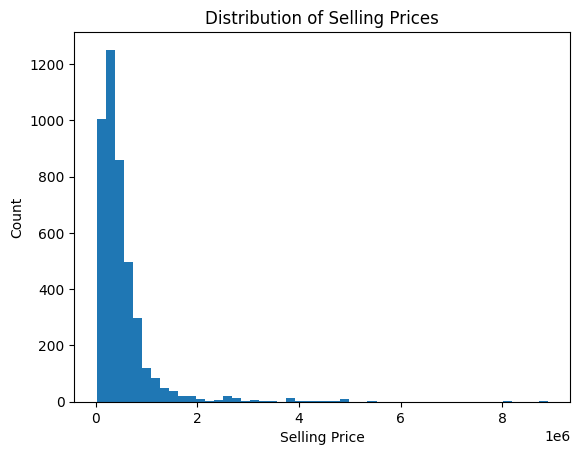

In [15]:
#EDA: distribution of selling prices, price vs. fuel type box plots, price vs. car age scatter plot
# Graph 1: Distribution of selling prices
plt.figure()
plt.hist(dataset['selling_price'], bins=50)
plt.title('Distribution of Selling Prices')
plt.xlabel('Selling Price')
plt.ylabel('Count')
plt.show()


<Figure size 640x480 with 0 Axes>

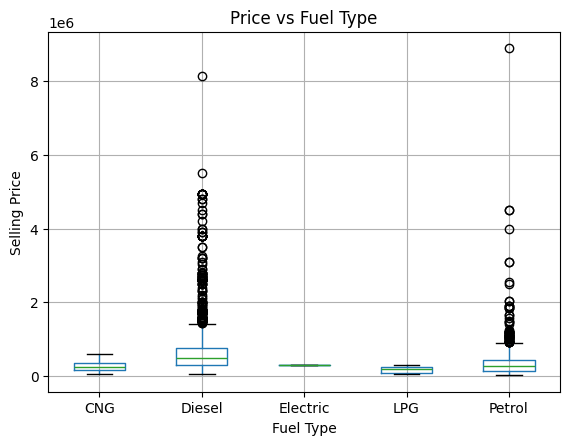

In [19]:
# Graph 2: Price vs Fuel Type Box Plot
plt.figure()
dataset.boxplot(column='selling_price', by='fuel')
plt.title('Price vs Fuel Type')
plt.suptitle('') # remove exta things
plt.xlabel('Fuel Type')
plt.ylabel('Selling Price')
plt.show()

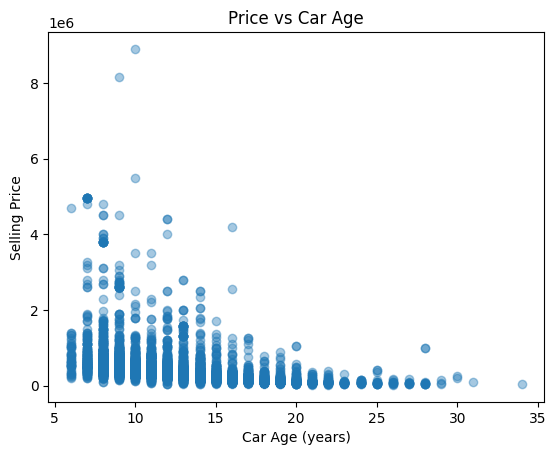

In [21]:
# Graph 3: Price vs Car Age Scatter Plot
plt.figure()
plt.scatter(dataset['car_age'], dataset['selling_price'], alpha=0.4)
plt.title('Price vs Car Age')
plt.xlabel('Car Age (years)')
plt.ylabel('Selling Price')
plt.show()

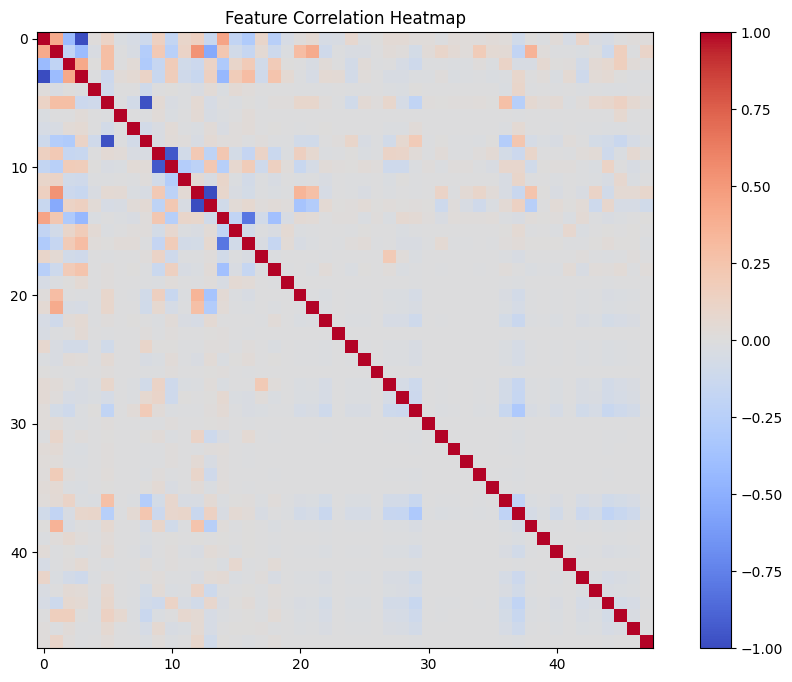

In [36]:
#encoding process
df_encoded = pd.get_dummies(dataset, columns=['fuel', 'seller_type', 'transmission', 'owner', 'brand'])

#Correlation Heatmap
plt.figure(figsize=(12,8))
corr = df_encoded.corr(numeric_only=True)
plt.imshow(corr, cmap='coolwarm')
plt.colorbar()
plt.title('Feature Correlation Heatmap')
plt.show()

In [41]:
from sklearn.model_selection import train_test_split
X = df_encoded.drop(['name', 'selling_price'], axis=1)
y = df_encoded['selling_price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [45]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
lr = LinearRegression()
rf = RandomForestRegressor(n_estimators=100, random_state=42)

lr.fit(X_train, y_train)
rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [49]:
#Evaluation of our Models
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
def evaluate(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{name} -> MAE: {mae:.0f} | RMSE: {rmse:.0f} | R2: {r2:.4f}")

evaluate("Linear Regression", y_test, lr.predict(X_test))
evaluate("Random Forest", y_test, rf.predict(X_test))

Linear Regression -> MAE: 185156 | RMSE: 378944 | R2: 0.5294
Random Forest -> MAE: 114953 | RMSE: 278436 | R2: 0.7460


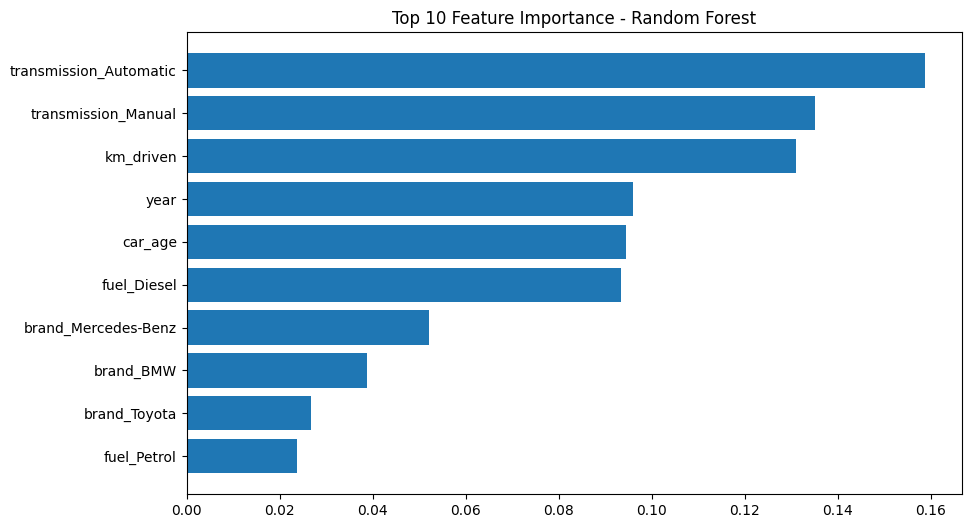

In [52]:
# Feature Importance 
importances = rf.feature_importances_
feat_imp = pd.DataFrame({'feature': X.columns, 'importance': importances}).sort_values('importance', ascending=False)

plt.figure(figsize=(10,6))
plt.barh(feat_imp.head(10)['feature'][::-1], feat_imp.head(10)['importance'][::-1])
plt.title('Top 10 Feature Importance - Random Forest')
plt.show()